# Лабораторная работа 1. BPE и Unigram токенизаторы с нуля (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 1:** языковое моделирование и токенизация

**Цель.** Понять токенизацию как задачу сжатия и оценить, как выбор токенизатора влияет на последующую модель.

**Что нужно сдать:**
1. Реализацию byte-level BPE и Unigram LM токенизаторов без сторонних библиотек (кроме `re`, `collections`, `math`).
2. Тесты корректности: \(\mathrm{decode}(\mathrm{encode}(x)) = x\) на всём корпусе и на произвольных байтах.
3. Сравнение с `sentencepiece` (совпадение сегментаций, скорость).
4. Графики «размер словаря — степень сжатия» для русского и английского корпусов и ответы на вопросы.

**Теория, которую нужно уметь воспроизвести на защите.** BPE — жадный алгоритм сжатия: на каждом шаге в словарь добавляется пара символов с наибольшей частотой. Unigram LM задаёт вероятностную модель сегментации
\[
p(x) = \sum_{s \in S(x)} \prod_{i} p(s_i),
\]
где \(S(x)\) — множество разбиений строки на подслова. Параметры оцениваются EM-алгоритмом: E-шаг вычисляет ожидаемые числа вхождений подслов через прямой и обратный проход (forward-backward), M-шаг нормирует их. Кодирование — поиск самой вероятной сегментации алгоритмом Витерби.

In [2]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import heapq

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.8.0.dev20250625+cu128, device=cuda, FAST_DEV_RUN=True


## 0. Данные

Используем два корпуса: англоязычный (Tiny Shakespeare) и русскоязычный («Война и мир»). В режиме `FAST_DEV_RUN` корпуса обрезаются.

In [3]:
en_text = load_shakespeare()
ru_text = load_russian()
LIMIT = 200_000 if FAST_DEV_RUN else 2_000_000
en_text, ru_text = en_text[:LIMIT], ru_text[:LIMIT]
print(len(en_text), len(ru_text))
print(ru_text[5000:5300])

200000 200000
ступом согласие прусского короля. Вы так красноречивы. Вы дадите мне чаю?
- Сейчас. A propos,- прибавила она, опять успокоиваясь,- нынче у меня два очень интересные человека,  le vicomte de Mortemart, il est allié aux Montmorency par les Rohans, одна из лучших фамилий Франции. Это один из хороших эм


## 1. Byte-level BPE

Алгоритм обучения:
1. Разбить текст на «предтокены» регулярным выражением (слова с ведущим пробелом, числа, пунктуация), чтобы слияния не пересекали границы слов.
2. Представить каждый предтокен как последовательность байтов UTF-8 (идентификаторы 0–255).
3. Повторять `vocab_size - 256` раз: найти самую частую соседнюю пару, создать новый токен, заменить все вхождения пары.

Наивный пересчёт всех пар на каждом шаге стоит \(O(\text{корпус})\), поэтому храните счётчики пар и индекс «пара → предтокены, где она встречается», обновляя их только для затронутых предтокенов.

In [4]:
import re
from collections import Counter, defaultdict

PRETOKEN_RE = re.compile(r" ?[^\W\d_]+| ?\d{1,3}| ?[^\s\w]+| ?_+|\s+(?!\S)|\s+", re.UNICODE)

def pretokenize(text):
    return PRETOKEN_RE.findall(text)

assert "".join(pretokenize("Hello, мир! 12345  x")) == "Hello, мир! 12345  x"
print(pretokenize("Hello, мир! 12345  x"))

['Hello', ',', ' мир', '!', ' 123', '45', ' ', ' x']


In [5]:
def merge_word(word, pair, new_id):
    """Заменяет все вхождения pair в кортеже word на new_id (слева направо, без перекрытий)."""
    result = []
    pair_len = len(pair)

    if pair_len == 0:
        return word
        
    i = 0
    n = len(word)
    
    while i < n:
        if word[i:i + pair_len] == pair:
            result.append(new_id)
            i += pair_len  
        else:
            result.append(word[i])
            i += 1
            
    return tuple(result)

assert merge_word((1, 2, 3, 1, 2), (1, 2), 9) == (9, 3, 9)
assert merge_word((1, 1, 1), (1, 1), 7) == (7, 1)

In [6]:
class ByteBPE:
    def __init__(self):
        self.merges = {}                       # (a, b) -> new_id, порядок вставки = ранг
        self.vocab = {i: bytes([i]) for i in range(256)}
        self._cache = {}

    def train(self, text, vocab_size, verbose=False):
        assert vocab_size >= 256
        words = Counter(tuple(t.encode("utf-8")) for t in pretokenize(text))
        
        word_list = list(words.keys()); counts = [words[w] for w in word_list]
        # TODO: ваш код (счётчик пар + индекс pair -> множество номеров слов, инкрементальное обновление)
        pairs_counter = Counter()
        where = defaultdict(set)
        
        for i, w in enumerate(word_list):
            for p in zip(w, w[1:]): pairs_counter[p] += counts[i]; where[p].add(i)
        
        heap = [(-c, p) for p, c in pairs_counter.items()]; heapq.heapify(heap)
        
        while len(self.vocab)<vocab_size and heap:
            c, best = heapq.heappop(heap)              # устаревшая запись кучи

            if -c != pairs_counter.get(best, 0): continue  
            if -c < 2: break

            changed = set()
            
            for i in where.pop(best, ()):
                word, freq = word_list[i], counts[i]
                for p in zip(word, word[1:]): pairs_counter[p] -= freq; changed.add(p)
                word_list[i] = merge_word(word, best, len(self.vocab))
                
                for p in zip(word_list[i], word_list[i][1:]): pairs_counter[p] += freq; where[p].add(i); changed.add(p)
                
            pairs_counter.pop(best, None)
            
            new_id = len(self.vocab)
            self.merges[best] = new_id
            self.vocab[new_id] = self.vocab[best[0]] + self.vocab[best[1]]
            
            for p in changed:
                if pairs_counter.get(p, 0) > 0: heapq.heappush(heap, (-pairs_counter[p], p))
                else: pairs_counter.pop(p, None)
        return self

    def _encode_chunk(self, chunk):
        if chunk in self._cache:
            return self._cache[chunk]
        ids = tuple(chunk.encode("utf-8"))
        
        for pair, new_id in self.merges.items():
            ids = merge_word(ids, pair, new_id)
            
        result = list(ids)
        self._cache[chunk] = result
        return result

    def encode(self, text):
        out = []
        for ch in pretokenize(text):
            out.extend(self._encode_chunk(ch))
        return out

    def decode(self, ids):
        token_bytes = b''.join(self.vocab[i] for i in ids)
        return token_bytes.decode('utf-8', errors='replace')

t0 = time.time()
bpe_en = ByteBPE().train(en_text, 1000)
print(f"обучение: {time.time() - t0:.1f} c, токенов в словаре: {len(bpe_en.vocab)}")
print([bpe_en.vocab[i] for i in list(bpe_en.vocab)[256:276]])

обучение: 0.2 c, токенов в словаре: 1000
[b' t', b'he', b'ou', b' a', b' s', b' w', b're', b'ha', b' the', b'in', b' m', b'nd', b' b', b'er', b'it', b'is', b'or', b'on', b'll', b' y']


### Тесты корректности

Проверьте обратимость на всём корпусе, на тексте на другом языке, на эмодзи и на случайных байтах, декодированных как UTF-8 с заменой.

In [7]:
def check_roundtrip(tok, text):
    return tok.decode(tok.encode(text)) == text

assert check_roundtrip(bpe_en, en_text)
assert check_roundtrip(bpe_en, ru_text[:20000])
assert check_roundtrip(bpe_en, "Ёжик 🦔 и 数学 — test\t\n  ")
rnd = bytes(np.random.randint(0, 256, 5000).tolist()).decode("utf-8", errors="replace")
assert check_roundtrip(bpe_en, rnd)
print("Все тесты обратимости пройдены")

Все тесты обратимости пройдены


## 2. Unigram LM токенизатор

Работаем на уровне символов Unicode, пробел заменяем на `▁` и присоединяем к началу слова (как в SentencePiece).

1. **Начальный словарь:** все символы корпуса + самые частые подстроки длины 2…`max_len` (в несколько раз больше целевого размера).
2. **E-шаг:** для каждого слова прямой проход \(\alpha_j = \log\sum_{i<j} \exp(\alpha_i + \log p(x_{i:j}))\), обратный проход \(\beta\); ожидаемое число вхождений подслова \(x_{i:j}\) — \(\exp(\alpha_i + \log p(x_{i:j}) + \beta_j - \log Z)\), умноженное на частоту слова.
3. **M-шаг:** \(p(s) \propto \mathbb{E}[\text{count}(s)]\).
4. **Прунинг:** удалить долю подслов с наименьшей вероятностью (одиночные символы не удалять), повторять до целевого размера словаря.

Это упрощённая версия: SentencePiece удаляет подслова по приросту правдоподобия корпуса при их удалении, а не по вероятности.

In [18]:
def logsumexp2(a, b):
    if a == -math.inf: return b
    if b == -math.inf: return a
    m = max(a, b); return m + math.log(math.exp(a - m) + math.exp(b - m))

def words_of(text):
    return Counter("▁" + w for w in text.split())

class UnigramTokenizer:
    def __init__(self, max_len=8):
        self.max_len = max_len; self.logp = {}

    def _forward_backward(self, w):
        """Возвращает (logZ, словарь ожидаемых вхождений подслов) для одного слова."""
        n = len(w)
        # TODO: ваш код
        alpha = [0.0] + [-math.inf] * n
        for i in range(1, n + 1):
            for j in range(max(0, i - self.max_len), i):
                piece = w[j:i]
                lp = self.logp.get(piece)
                if lp is not None:
                    alpha[i] = logsumexp2(
                        alpha[i],
                        alpha[j] + lp
                    )

        beta = [-math.inf] * n + [0.0]
        for j in range(n - 1, -1, -1):
            for i in range(j + 1, min(n, j + self.max_len) + 1):
                piece = w[j:i]
                lp = self.logp.get(piece)
                if lp is not None:
                    beta[j] = logsumexp2(
                        beta[j],
                        lp + beta[i]
                    )

        logZ = alpha[n]
        expected = defaultdict(float)

        for i in range(1, n + 1):
            for j in range(max(0, i - self.max_len), i):
                piece = w[j:i]
                lp = self.logp.get(piece)
                if lp is not None:
                    expected[piece] += math.exp(
                        alpha[j] + lp + beta[i] - logZ
                    )

        return logZ, expected

    def train(self, text, vocab_size, init_factor=4, prune_frac=0.2, em_iters=2, verbose=True):
        words = words_of(text)
        chars = Counter(); subs = Counter()
        for w, c in words.items():
            for ch in w: chars[ch] += c
            for i in range(len(w)):
                for j in range(i + 2, min(len(w), i + self.max_len) + 1):
                    subs[w[i:j]] += c
        init = dict(chars); init.update(dict(subs.most_common(init_factor * vocab_size)))
        total = sum(init.values()); self.logp = {s: math.log(c / total) for s, c in init.items()}
        self.chars = set(chars)
        while True:
            for _ in range(em_iters):
                # TODO: ваш код (E-шаг по всем словам с весом частоты, затем M-шаг; накопите log-правдоподобие)
                expected_total = defaultdict(float)
                ll = 0.0

                for w, freq in words.items():
                    logZ, expected = self._forward_backward(w)
                    ll += freq * logZ

                    for piece, count in expected.items():
                        expected_total[piece] += freq * count

                total = sum(expected_total.values())
                self.logp = {
                    piece: math.log(count / total)
                    for piece, count in expected_total.items()
                    if count > 0
                }
            if verbose: print(f"|V|={len(self.logp):6d}  log-likelihood={ll:.4e}")
            if len(self.logp) <= vocab_size: break
            # TODO: ваш код (удалите prune_frac наименее вероятных подслов длины > 1, не опускаясь ниже vocab_size)
            removable = [
                piece for piece in self.logp
                if len(piece) > 1
            ]
            removable.sort(key=self.logp.get)

            n_remove = min(
                max(1, int(len(self.logp) * prune_frac)),
                len(self.logp) - vocab_size,
                len(removable),
            )

            for piece in removable[:n_remove]:
                del self.logp[piece]
        
            return self

    def segment(self, w):
        """Витерби: самая вероятная сегментация слова."""
        n = len(w)
        # TODO: ваш код
        best = [0.0] + [-math.inf] * n
        back = [-1] * (n + 1)

        for i in range(1, n + 1):
            for j in range(max(0, i - self.max_len), i):
                piece = w[j:i]
                lp = self.logp.get(piece)

                if lp is None or best[j] == -math.inf:
                    continue

                score = best[j] + lp
                if score > best[i]:
                    best[i] = score
                    back[i] = j

        if best[n] == -math.inf:
            raise ValueError(f"Слово нельзя сегментировать: {w!r}")

        pieces = []
        i = n

        while i > 0:
            j = back[i]
            pieces.append(w[j:i])
            i = j

        return pieces[::-1]

    def encode(self, text):
        # Сохраняем точную обратимость: пробельные символы кодируются отдельными «токенами»
        out = []
        for part in re.split(r"(\s+)", text):
            if not part: continue
            if part.isspace():
                if part == " ": continue           # одиночный пробел кодируется префиксом ▁ следующего слова
                out.append(part)
            else:
                out.extend(self.segment("▁" + part))
        return out

    def decode(self, pieces):
        s, prev_ws = "", True
        for p in pieces:
            if p.startswith("▁"):
                s += ("" if prev_ws else " ") + p[1:]; prev_ws = False
            else:
                s += p; prev_ws = p.isspace()
        return s

t0 = time.time()
# uni_en = UnigramTokenizer().train(en_text[: (60_000 if FAST_DEV_RUN else 500_000)], 1000)

uni_en = UnigramTokenizer().train(en_text, 1000)
print(f"обучение: {time.time() - t0:.1f} c")
print(uni_en.encode("To be, or not to be: that is the question."))

|V|=  4061  log-likelihood=-3.9109e+05
обучение: 0.6 c
['▁To', '▁be', ',', '▁or', '▁not', '▁to', '▁be', ':', '▁that', '▁is', '▁the', '▁que', 's', 'tion.']


**Замечание об обратимости.** Наш Unigram-токенизатор работает с токенами-строками, а не с байтами. Обратимость гарантирована для текстов из одиночных пробелов между словами; проверьте её на корпусе, нормализованном так, как это делает SentencePiece (подряд идущие пробелы сжаты, переводы строк сохранены).

In [9]:
def normalize_spaces(t):
    t = re.sub(r"[ \t]+", " ", t)
    return re.sub(r" *\n *", "\n", t).strip()

sample = normalize_spaces(en_text[:20000])
assert uni_en.decode(uni_en.encode(sample)) == sample
print("Unigram: обратимость на нормализованном корпусе выполнена")

Unigram: обратимость на нормализованном корпусе выполнена


## 3. Сравнение с SentencePiece

Обучите `sentencepiece` в режимах `bpe` и `unigram` с тем же размером словаря и сравните:
- долю слов, сегментированных одинаково с вашей реализацией;
- среднее число токенов на слово;
- время обучения и кодирования.

Полного совпадения ожидать не нужно: SentencePiece использует другой прунинг, нормализацию и обработку редких символов.

In [10]:
try:
    import sentencepiece as spm
except ImportError:
    os.system("pip -q install sentencepiece"); import sentencepiece as spm

corpus_file = DATA / "en_corpus.txt"; corpus_file.write_text(en_text, encoding="utf-8")
spm_models = {}
for mtype in ("bpe", "unigram"):
    t0 = time.time()
    spm.SentencePieceTrainer.train(input=str(corpus_file), model_prefix=str(ARTIFACTS / f"spm_{mtype}"),
                                   vocab_size=1000, model_type=mtype, character_coverage=1.0,
                                   max_sentence_length=100000, minloglevel=2)
    spm_models[mtype] = spm.SentencePieceProcessor(model_file=str(ARTIFACTS / f"spm_{mtype}.model"))
    print(mtype, f"обучение {time.time() - t0:.1f} c")

bpe обучение 0.1 c
unigram обучение 0.3 c


In [19]:
def agreement(seg_a, seg_b, words):
    same = sum(seg_a(w) == seg_b(w) for w in words)
    return same / len(words)

test_words = [w for w, _ in words_of(en_text[150_000:]).most_common(2000)]
ours_uni = lambda w: uni_en.segment(w)
sp_uni = lambda w: [p for p in spm_models["unigram"].encode(w[1:], out_type=str)]
ours_bpe = lambda w: [bpe_en.vocab[i].decode("utf-8", "replace") for i in bpe_en.encode(" " + w[1:])]
sp_bpe = lambda w: [p.replace("▁", " ") for p in spm_models["bpe"].encode(w[1:], out_type=str)]

# TODO: ваш код (посчитайте agreement, токены на слово и время кодирования для четырёх токенизаторов)


In [20]:
segmenters = {
    "ours_unigram": ours_uni,
    "sp_unigram": sp_uni,
    "ours_bpe": ours_bpe,
    "sp_bpe": sp_bpe,
}

encoding_stats = {}

for name, segmenter in segmenters.items():
    t0 = time.perf_counter()

    segmentations = [
        segmenter(w)
        for w in test_words
    ]

    elapsed = time.perf_counter() - t0
    n_tokens = sum(len(pieces) for pieces in segmentations)

    encoding_stats[name] = {
        "tokens_per_word": n_tokens / len(test_words),
        "encoding_time": elapsed,
        "words_per_second": len(test_words) / elapsed,
    }

for name, stats in encoding_stats.items():
    print(
        f"{name:15s} "
        f"tokens/word={stats['tokens_per_word']:.3f}  "
        f"time={stats['encoding_time']:.4f} s  "
        f"words/s={stats['words_per_second']:.1f}"
    )

print(
    "Unigram agreement:",
    agreement(ours_uni, sp_uni, test_words)
)

print(
    "BPE agreement:",
    agreement(ours_bpe, sp_bpe, test_words)
)

ours_unigram    tokens/word=2.393  time=0.0155 s  words/s=128884.3
sp_unigram      tokens/word=2.919  time=0.0052 s  words/s=384216.4
ours_bpe        tokens/word=3.150  time=0.0552 s  words/s=36247.8
sp_bpe          tokens/word=2.872  time=0.0059 s  words/s=340055.1
Unigram agreement: 0.348
BPE agreement: 0.728


## 4. Размер словаря, язык и степень сжатия

Для словарей 1k, 8k, 32k (в `FAST_DEV_RUN`: 300, 1000, 2000) обучите BPE на английском и русском корпусах и измерьте на отложенной части:
- **fertility** — среднее число токенов на слово;
- **сжатие** — байтов UTF-8 на токен;
- **долю редких токенов** — долю токенов словаря, встретившихся в отложенной части менее 5 раз.

Обучающая и отложенная части не должны пересекаться.

In [14]:
VOCABS = [300, 1000, 2000] if FAST_DEV_RUN else [1000, 8000, 32000]

def tokenizer_stats(tok, text, vocab_size):
    ids = tok.encode(text)

    n_tokens = len(ids)
    n_words = len(text.split())
    n_bytes = len(text.encode("utf-8"))

    counts = Counter(ids)

    fertility = n_tokens / n_words
    bytes_per_token = n_bytes / n_tokens
    rare_share = (
        sum(counts[i] < 5 for i in range(vocab_size))
        / vocab_size
    )

    return {
        "fertility": fertility,
        "bytes_per_token": bytes_per_token,
        "rare_share": rare_share,
    }

results = {}
for lang, text in [("en", en_text), ("ru", ru_text)]:
    cut = int(0.8 * len(text)); train_t, test_t = text[:cut], text[cut:]
    for V in VOCABS:
        tok = ByteBPE().train(train_t, V)
        results[(lang, V)] = tokenizer_stats(tok, test_t, len(tok.vocab))
        print(lang, V, {k: round(v, 3) for k, v in results[(lang, V)].items()})

en 300 {'fertility': 4.062, 'bytes_per_token': 1.371, 'rare_share': 0.657}
en 1000 {'fertility': 2.505, 'bytes_per_token': 2.223, 'rare_share': 0.476}
en 2000 {'fertility': 2.109, 'bytes_per_token': 2.641, 'rare_share': 0.725}
ru 300 {'fertility': 5.543, 'bytes_per_token': 1.942, 'rare_share': 0.557}
ru 1000 {'fertility': 2.778, 'bytes_per_token': 3.875, 'rare_share': 0.394}
ru 2000 {'fertility': 2.298, 'bytes_per_token': 4.683, 'rare_share': 0.641}


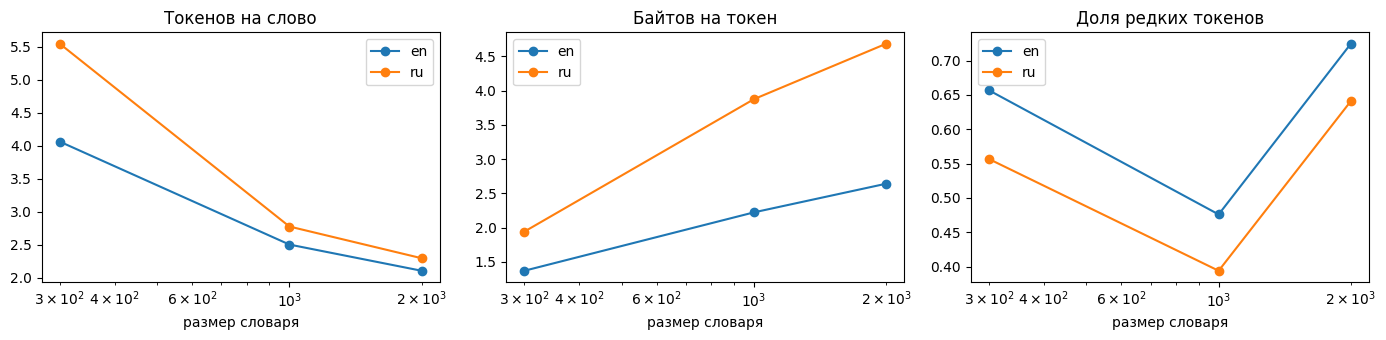

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, key, title in zip(axes, ["fertility", "bytes_per_token", "rare_share"],
                          ["Токенов на слово", "Байтов на токен", "Доля редких токенов"]):
    for lang in ("en", "ru"):
        ax.plot(VOCABS, [results[(lang, V)][key] for V in VOCABS], "o-", label=lang)
    ax.set_xscale("log"); ax.set_xlabel("размер словаря"); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.savefig(ARTIFACTS / "lab01_vocab_curves.png", dpi=120); plt.show()

## 5. Токенизация чисел и кода

Посмотрите, как токенизатор разбивает числа разной длины и фрагменты кода. Найдите примеры, где одно и то же число разбивается по-разному в зависимости от контекста (с пробелом и без), и объясните, почему это мешает модели выполнять арифметику.

In [ ]:
examples = ["12345 + 67890 = 80235", "x12345", " 1000000", "3.14159", "def f(x):\n    return x**2"]
for e in examples:
    print(repr(e), "->", [bpe_en.vocab[i].decode("utf-8", "replace") for i in bpe_en.encode(e)])

## Вопросы

1. Почему BPE-обучение можно рассматривать как жадный алгоритм сжатия? Что он оптимизирует на каждом шаге и почему результат не оптимален глобально? - На каждом шаге BPE объединяет наиболее частую пару соседних токенов, максимально уменьшая текущую длину корпуса: например, a b a b → ab ab. Глобальный оптимум не гарантируется, поскольку каждое слияние изменяет частоты будущих пар, а уже сделанные решения не пересматриваются. Например для a b c выбор пары ab затирает границу пары bc.
2. Почему при одинаковом размере словаря русский текст даёт больше токенов на слово, чем английский? Как это влияет на стоимость инференса и эффективную длину контекста? - Из-за богатой морфологии русские слова имеют больше словоформ, а кириллические буквы занимают два байта UTF-8, поэтому часть слияний BPE расходуется на восстановление символов из байтов. Большее число токенов повышает стоимость инференса и уменьшает объём текста, помещающийся в контекст фиксированной длины.
3. Чем Unigram LM лучше BPE с вероятностной точки зрения? Что даёт возможность сэмплировать сегментации (subword regularization)? - Unigram задаёт вероятности токенов и учитывает все возможные сегментации слова, тогда как BPE строит одну сегментацию жадными слияниями. Сэмплирование вариантов, например un|happy и u|n|happy, работает как аугментация и повышает устойчивость модели к редким словам и опечаткам.
4. Почему perplexity моделей с разными токенизаторами нельзя сравнивать напрямую и как перейти к bits-per-byte? - Perplexity измеряется на токен, поэтому её нельзя напрямую сравнивать у моделей с токенами разного размера. Используют $\mathrm{bpb} = -\frac{\sum_t \log_2 p(x_t)}{N_{\mathrm{bytes}}}$,
или
$\mathrm{bpb} = \log_2(\mathrm{PPL})\frac{N_{\mathrm{tok}}}{N_{\mathrm{bytes}}}$.; меньшее значение означает лучшее сжатие.
5. Предложите способ токенизации чисел, облегчающий арифметику, и обоснуйте его. - Числа можно всегда разбивать на отдельные цифры: 12345 → [1,2,3,4,5], независимо от пробела или другого контекста. Это сохраняет поразрядную структуру и облегчает обучение сложению и переносу, хотя увеличивает длину последовательности.